### Timeless Lesson in Modeling

In [3]:
def model(x, w, b):
    return w * x + b

w = 2
b = 1

print(model(5, w, b))

11


### Visualizing the Data

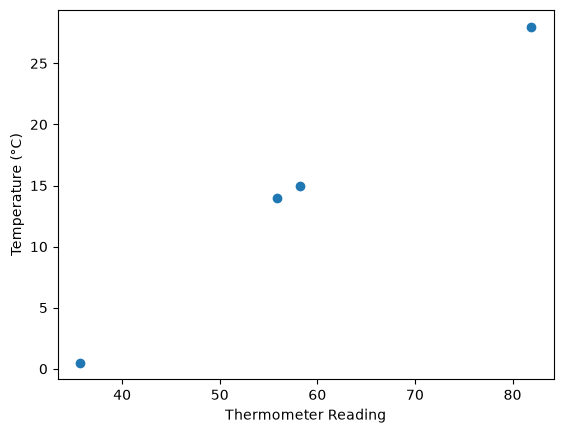

In [4]:
import torch
import matplotlib.pyplot as plt

X = torch.tensor([35.7,55.9,58.2,81.9])
Y = torch.tensor([0.5,14.0,15.0,28.0])

plt.scatter(X, Y)
plt.xlabel("Thermometer Reading")
plt.ylabel("Temperature (°C)")
plt.show()

### Less Loss Is What We Want

In [6]:
import torch

# Data
X = torch.tensor([35.7,55.9,58.2,81.9])
Y = torch.tensor([0.5,14.0,15.0,28.0])

# Parameters
w = torch.tensor(0.5)
b = torch.tensor(-17.0)

# Model
def model(x, w, b):
    return w * x + b

# Loss
def loss_fn(prediction, actual):
    return ((prediction - actual) ** 2).mean()

# Prediction
prediction = model(X, w, b)

# Loss
loss = loss_fn(prediction, Y)

print("Prediction:", prediction)
print("Loss:", loss)

Prediction: tensor([ 0.8500, 10.9500, 12.1000, 23.9500])
Loss: tensor(8.5594)


### Decreasing Loss
New Parameter = Old Parameter − Learning Rate × Gradient

In [ ]:
# Update parameters
with torch.no_grad():
    w -= learning_rate * w.grad
    b -= learning_rate * b.grad

### Getting Analytical

In [ ]:
loss.backward()

print(w.grad)
print(b.grad)

### Iterating to Fit the Model(Repeat)

In [ ]:
for epoch in range(100):

    prediction = model(X)

    loss = loss_fn(prediction, Y)

    loss.backward()

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

        w.grad.zero_()
        b.grad.zero_()

### Normalizing Inputs

In [ ]:
X = X / 10 & t_un = 0.1 * t_u

### Gradient Automatically

In [8]:
import torch

w = torch.tensor(0.5, requires_grad=True)

loss = (w * 2 - 4) ** 2

loss.backward()

print(w.grad)

tensor(-12.)


### Optimizers à la Carte

In [ ]:
import torch.optim as optim

optimizer = optim.SGD([w, b], lr=0.01)

optimizer.zero_grad()

loss.backward()

optimizer.step()

## Full Code 

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim

# Data
X = torch.tensor([[1.],[2.],[3.],[4.]])
Y = torch.tensor([[3.],[5.],[7.],[9.]])

# Model
model = nn.Linear(1,1)

# Loss
loss_fn = nn.MSELoss()

# Optimizer
optimizer = optim.SGD(model.parameters(), lr=0.1)

# Training
for epoch in range(100):

    prediction = model(X)

    loss = loss_fn(prediction, Y)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

print(model.weight)
print(model.bias)

Parameter containing:
tensor([[2.0062]], requires_grad=True)
Parameter containing:
tensor([0.9818], requires_grad=True)


## Full Code

Epoch 100, Loss = 26.7035
Epoch 200, Loss = 13.5645
Epoch 300, Loss = 6.8903
Epoch 400, Loss = 3.5001
Epoch 500, Loss = 1.7779
Epoch 600, Loss = 0.9031
Epoch 700, Loss = 0.4588
Epoch 800, Loss = 0.2330
Epoch 900, Loss = 0.1184
Epoch 1000, Loss = 0.0601

Weight:
Parameter containing:
tensor([[2.1587]], requires_grad=True)

Bias:
Parameter containing:
tensor([18.4272], requires_grad=True)

Predictions:
tensor([[20.5859],
        [22.7445],
        [24.9032],
        [27.0618],
        [29.2205]])


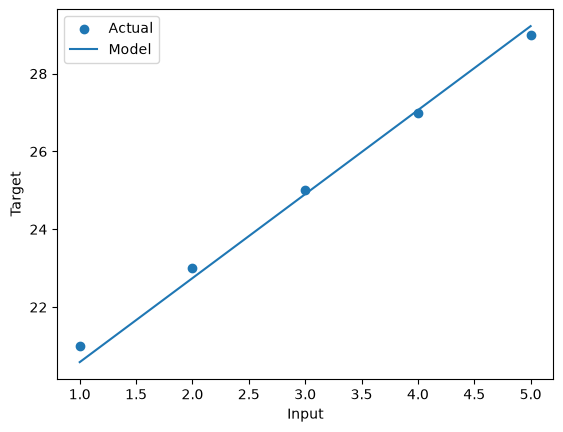

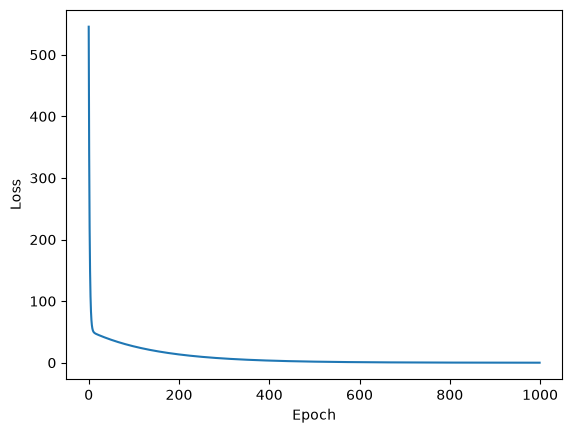

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ============================================
# 1. DATA
# ============================================

x = torch.tensor([
    [1.0],
    [2.0],
    [3.0],
    [4.0],
    [5.0]
])

y = torch.tensor([
    [21.0],
    [23.0],
    [25.0],
    [27.0],
    [29.0]
])


# ============================================
# 2. MODEL
# ============================================

model = nn.Linear(
    in_features=1,
    out_features=1
)


# ============================================
# 3. LOSS FUNCTION
# ============================================

loss_fn = nn.MSELoss()


# ============================================
# 4. OPTIMIZER
# ============================================

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)


# ============================================
# 5. TRAINING
# ============================================

epochs = 1000

loss_history = []

for epoch in range(epochs):

    # Forward pass
    prediction = model(x)

    # Calculate loss
    loss = loss_fn(
        prediction,
        y
    )

    # Clear old gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update parameters
    optimizer.step()

    # Save loss
    loss_history.append(
        loss.item()
    )

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1}, "
            f"Loss = {loss.item():.4f}"
        )


# ============================================
# 6. LEARNED PARAMETERS
# ============================================

print("\nWeight:")
print(model.weight)

print("\nBias:")
print(model.bias)


# ============================================
# 7. PREDICTION
# ============================================

with torch.no_grad():

    prediction = model(x)

print("\nPredictions:")
print(prediction)


# ============================================
# 8. VISUALIZE FIT
# ============================================

plt.scatter(
    x.numpy(),
    y.numpy(),
    label="Actual"
)

plt.plot(
    x.numpy(),
    prediction.numpy(),
    label="Model"
)

plt.xlabel("Input")
plt.ylabel("Target")
plt.legend()
plt.show()


# ============================================
# 9. VISUALIZE LOSS
# ============================================

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.show()